<a href="https://colab.research.google.com/github/J3remy1/east-river-water-quality/blob/main/notebooks/05_oxygen_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

url = "https://raw.githubusercontent.com/J3remy1/east-river-water-quality/main/data/estuary_2020_2025.csv"
data = pd.read_csv(url)
d = data.dropna(subset=["temp_c", "do_ppm", "salinity_ppt"])
d = d[d["do_ppm"] > 0]
len(d)

255

In [2]:
m1 = smf.ols("do_ppm ~ temp_c", data=d).fit()
print(m1.params.round(3))
print("R squared:", round(m1.rsquared, 3))

Intercept    10.567
temp_c       -0.131
dtype: float64
R squared: 0.028


In [3]:
m2 = smf.ols("do_ppm ~ temp_c + salinity_ppt", data=d).fit()
print(m2.summary().tables[1])
print("R squared:", round(m2.rsquared, 3))

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       10.5626      0.864     12.218      0.000       8.860      12.265
temp_c          -0.0979      0.048     -2.051      0.041      -0.192      -0.004
salinity_ppt    -0.0551      0.012     -4.427      0.000      -0.080      -0.031
R squared: 0.098


In [4]:
def do_saturation(temp_c, salinity_ppt):
    """Dissolved oxygen at saturation, mg/L, 1 atm (Weiss 1970)."""
    T = temp_c + 273.15
    A1, A2, A3, A4 = -173.4292, 249.6339, 143.3483, -21.8492
    B1, B2, B3 = -0.033096, 0.014259, -0.0017000
    ln_c = (A1 + A2 * (100 / T) + A3 * np.log(T / 100) + A4 * (T / 100)
            + salinity_ppt * (B1 + B2 * (T / 100) + B3 * (T / 100) ** 2))
    return np.exp(ln_c) * 1.42903

T0, S0 = d["temp_c"].mean(), d["salinity_ppt"].mean()
theory_temp = do_saturation(T0 + 0.5, S0) - do_saturation(T0 - 0.5, S0)
theory_sal = do_saturation(T0, S0 + 0.5) - do_saturation(T0, S0 - 0.5)
print("per degree C:", round(theory_temp, 3))
print("per ppt:", round(theory_sal, 3))

per degree C: -0.178
per ppt: -0.053


In [5]:
rows = []
for year, g in d.groupby("year"):
    m = smf.ols("do_ppm ~ temp_c + salinity_ppt", data=g).fit()
    rows.append({"year": year, "n": len(g),
                 "temp_coef": m.params["temp_c"],
                 "salinity_coef": m.params["salinity_ppt"]})
pd.DataFrame(rows).round(3)

,year,n,temp_coef,salinity_coef
0,2020,39,0.016,-0.138
1,2021,28,-0.265,-0.091
2,2022,37,-0.177,-0.078
3,2023,46,-0.347,0.003
4,2024,56,-0.062,-0.031
5,2025,49,0.161,-0.081


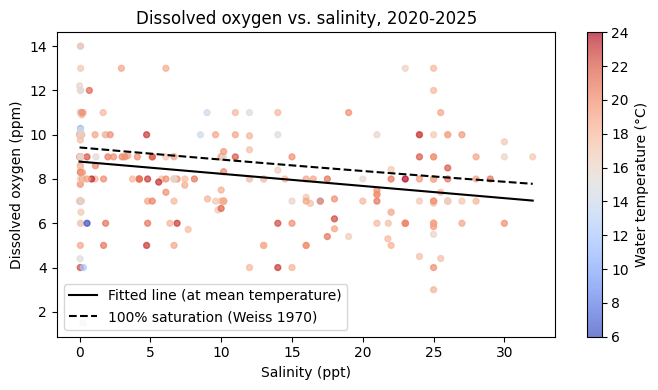

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sc = ax.scatter(d["salinity_ppt"], d["do_ppm"], c=d["temp_c"], cmap="coolwarm", s=18, alpha=0.7)
fig.colorbar(sc, label="Water temperature (°C)")
s = np.linspace(0, d["salinity_ppt"].max(), 50)
fitted = m2.params["Intercept"] + m2.params["temp_c"] * T0 + m2.params["salinity_ppt"] * s
ax.plot(s, fitted, color="black", label="Fitted line (at mean temperature)")
ax.plot(s, do_saturation(T0, s), color="black", linestyle="--", label="100% saturation (Weiss 1970)")
ax.set_xlabel("Salinity (ppt)")
ax.set_ylabel("Dissolved oxygen (ppm)")
ax.set_title("Dissolved oxygen vs. salinity, 2020-2025")
ax.legend()
plt.tight_layout()
plt.show()

In [7]:
for col in ["sat_fresh", "sat_salty"]:
    m = smf.ols(f"{col} ~ salinity_ppt", data=d).fit()
    lo, hi = m.conf_int().loc["salinity_ppt"]
    print(col, round(m.params["salinity_ppt"], 2), round(lo, 2), round(hi, 2))

sat_fresh -0.55 -0.8 -0.29
sat_salty -0.02 -0.3 0.25


**Findings**. In 255 readings from 2020–2025, dissolved oxygen fell by 0.055 ppm for each ppt of salinity, holding temperature fixed (95% CI −0.080 to −0.031). Oxygen solubility predicts 0.053 ppm per ppt at the average temperature and salinity in this data (Weiss 1970). The fitted line runs parallel to the 100% saturation line but sits below it: on average the water was about 93% saturated.

Measured with the freshwater table, saturation appears to drop 0.55 points per ppt, as if saltier water were more oxygen-starved. With the salinity-corrected calculation, the trend disappears (−0.03 points per ppt, 95% CI −0.30 to +0.25). The apparent pattern comes from the chart, not the river.

**Limits.** The model explains about 10% of the variation (R² = 0.098). The temperature effect is weaker than solubility predicts (−0.098 vs. −0.178 ppm per °C), likely because each sampling day covers a narrow temperature range. Year-by-year coefficients vary widely, from −0.138 to +0.003 for salinity, and the 2023 salinity effect is near zero. Salty sites cluster near the harbor, so salinity may stand in for other site differences. Most readings come from test kits that report whole numbers.